# Compulsory Assignement 4, Dat200
**Group4** Lasse Lindholm & Brage Bromset Bestvold

# Imports

In [81]:
# for preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# our 4 different classifers to test
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

from sklearn.preprocessing import OneHotEncoder

# for feature selection
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline      import make_pipeline
from sklearn.decomposition import PCA

# To stop warnings from
import warnings
warnings.filterwarnings("ignore", category=Warning, module="sklearn")

# Reading/Loading the data

In [82]:
train = pd.read_csv("trainCA4DAT200.csv")
test = pd.read_csv("testCA4DAT200.csv")
train.head()

,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


# Data Exploration


In [83]:


categorical_data = ["AreaCode", "InternationalPlan", "VoiceMailPlan"]
# ["State","AreaCode", "InternationalPlan", "VoiceMailPlan"]
train = train.drop(columns=["State"])

# Bare å kopiere state inn igjen, jeg tester akkurat nå

ohe = OneHotEncoder(sparse_output=False)
data = ohe.fit_transform(train[categorical_data])



data = pd.DataFrame(
    data,
    columns=ohe.get_feature_names_out(categorical_data),
    index=train.index
)



train = pd.concat([
    train.drop(columns=categorical_data),
    data],
    axis=1
)

train.head()


,CustomerId,AccountLength,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,...,IntlCharge,CustomerServiceCalls,Churn,AreaCode_408,AreaCode_415,AreaCode_510,InternationalPlan_no,InternationalPlan_yes,VoiceMailPlan_no,VoiceMailPlan_yes
0,952920,87,0,223.2,109,37.94,127.5,86,10.84,289.3,...,3.92,3,0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
1,895150,114,28,225.8,94,38.39,193.0,117,16.41,232.4,...,2.27,4,0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,636987,55,0,180.1,77,30.62,235.5,98,20.02,169.4,...,3.00,0,0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,538188,100,0,68.5,110,11.65,337.1,115,28.65,205.2,...,3.27,0,0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
4,947531,74,46,277.7,109,47.21,270.0,114,22.95,165.3,...,2.81,1,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


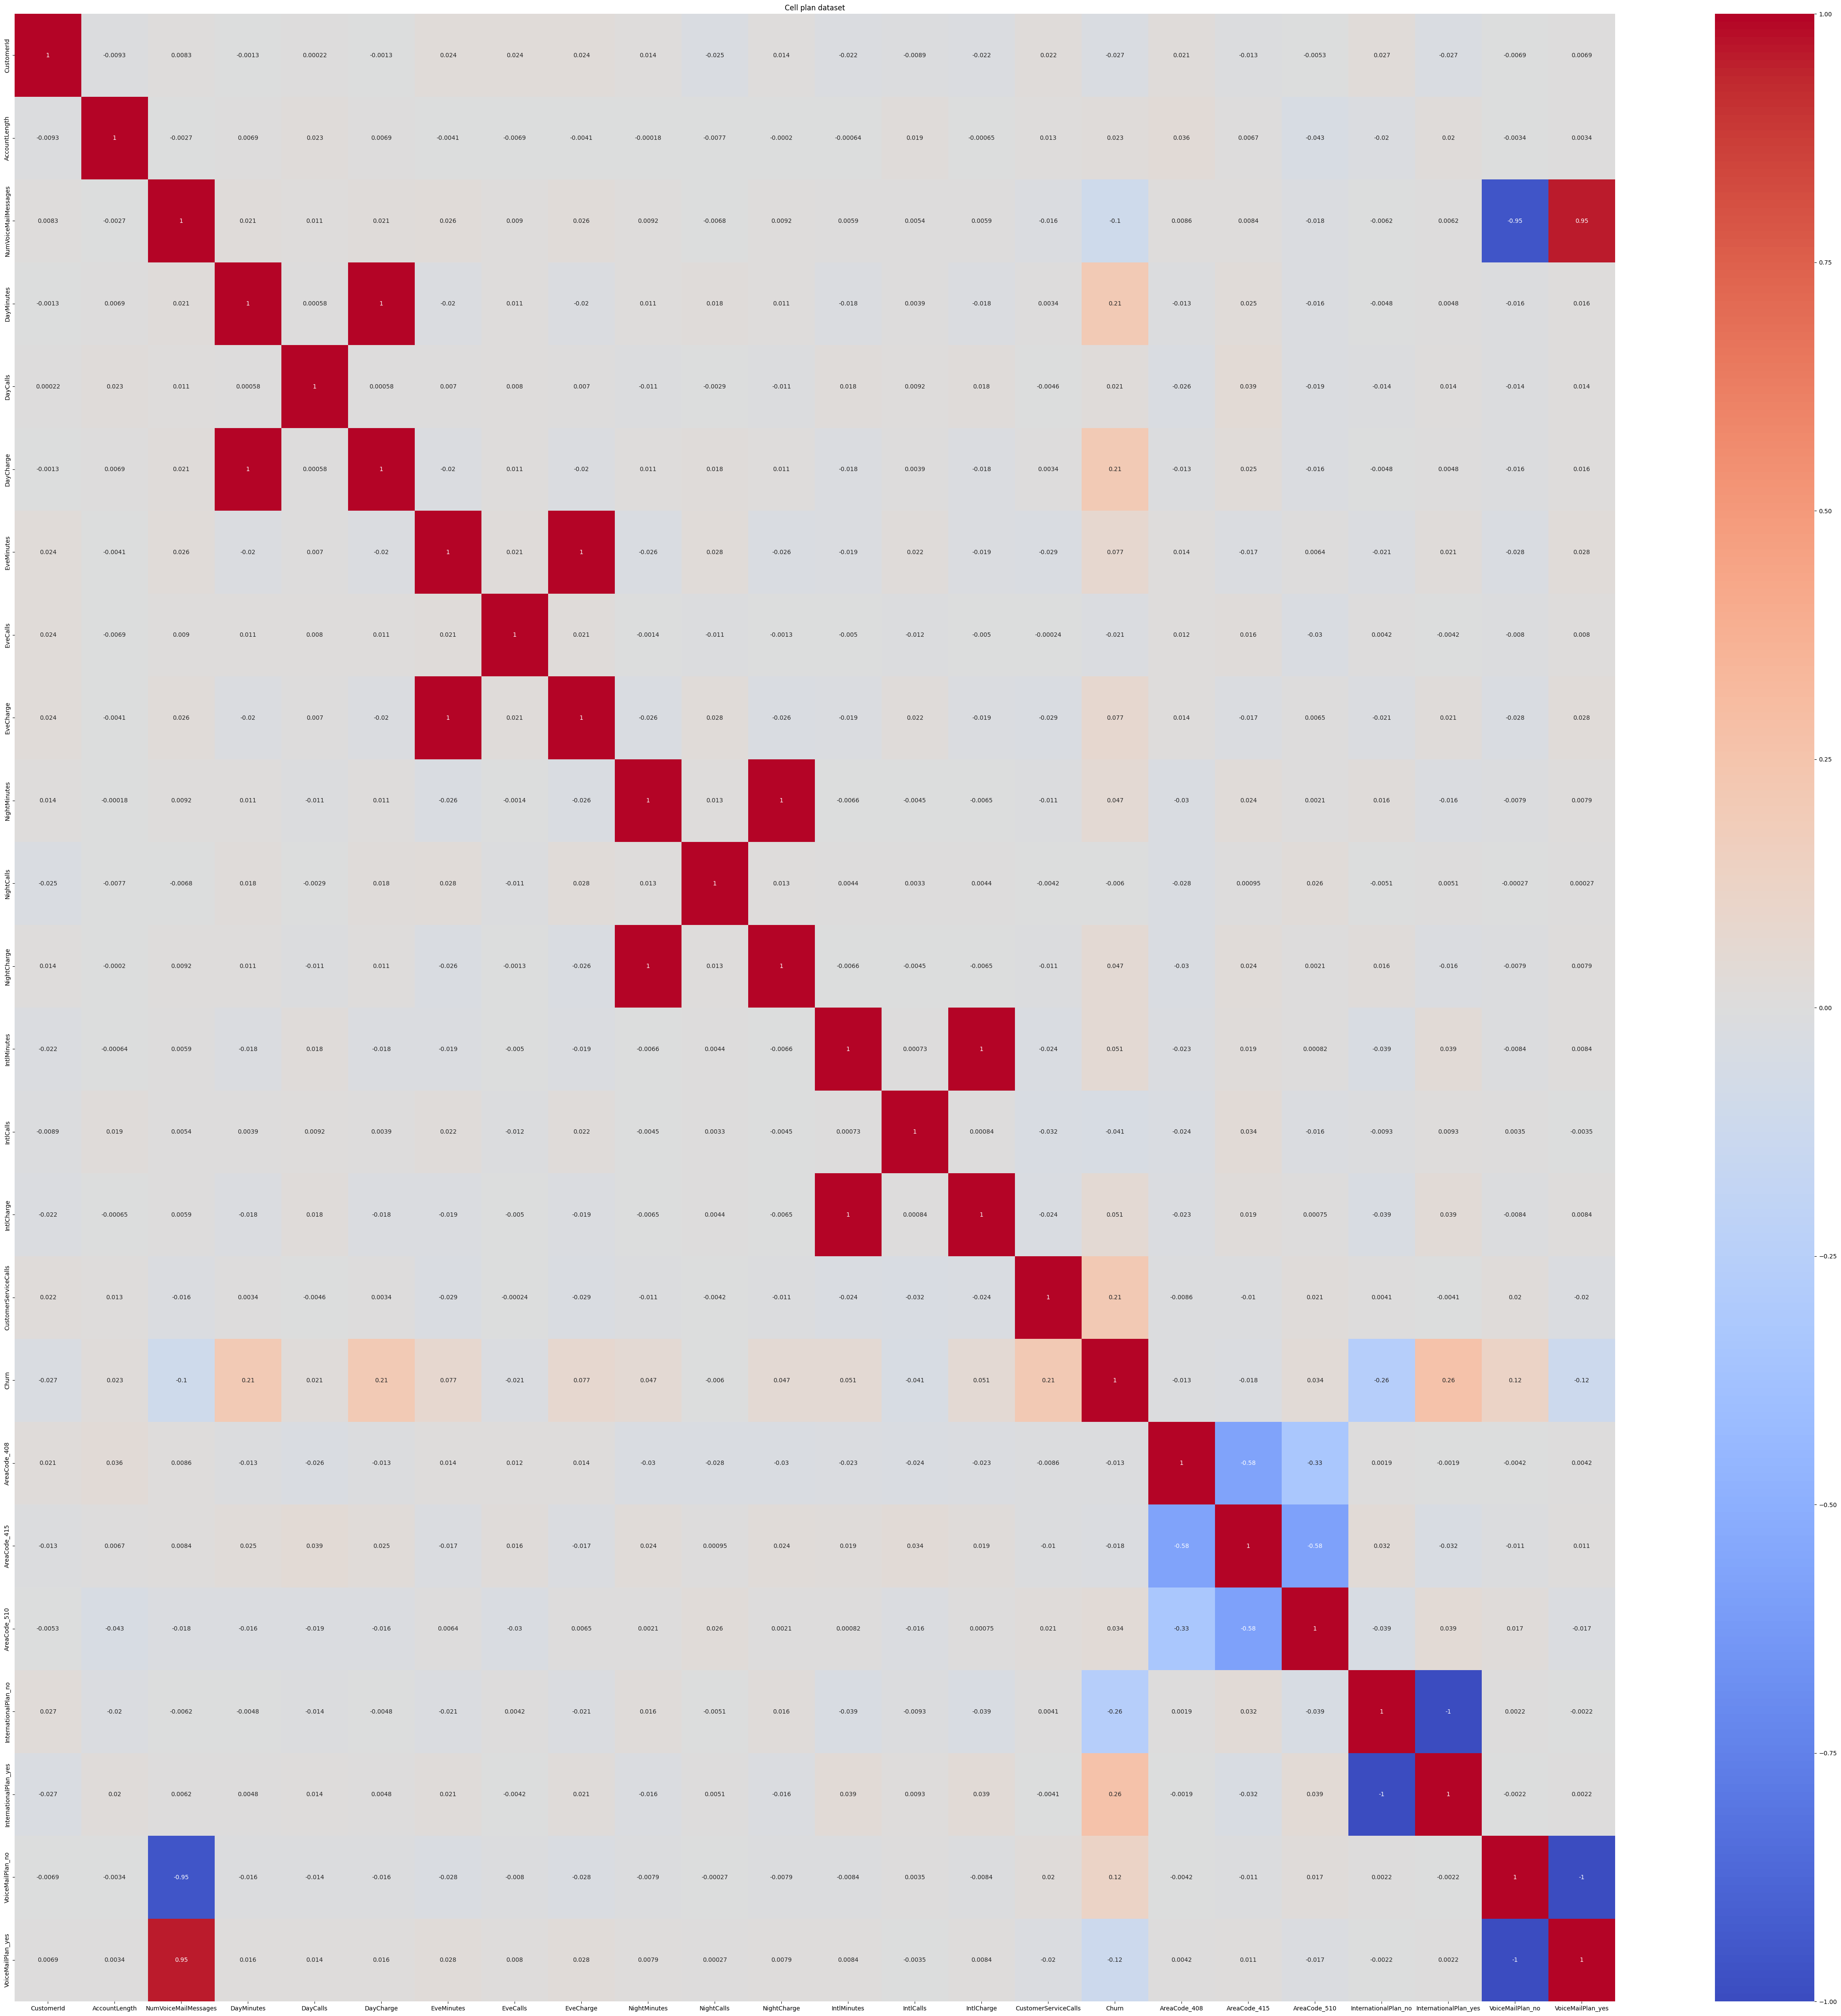

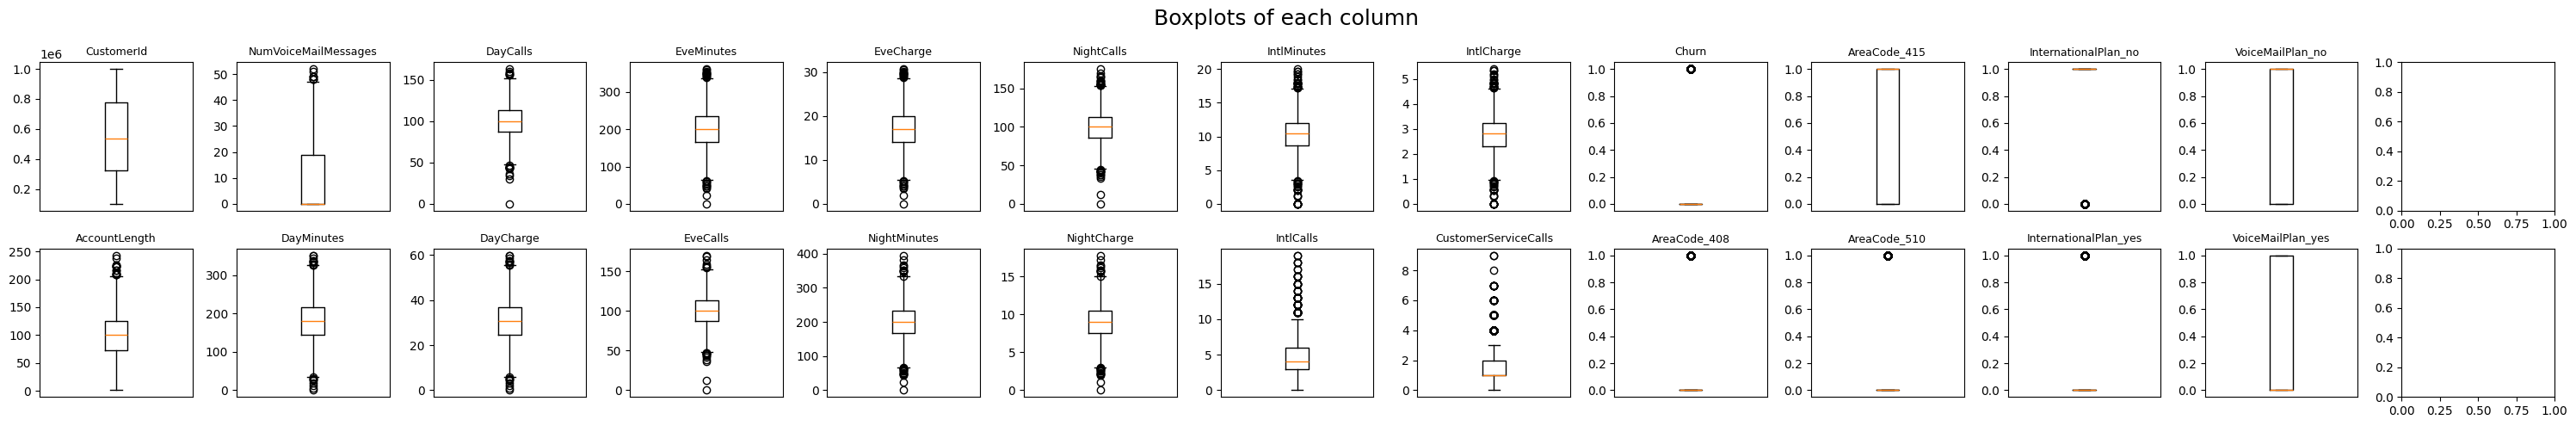

In [84]:


#sns.pairplot(train, vars=train.keys(), hue="Churn")

#plt.show()



# Modified correlation heatmap taken from the 04_correlationmap.ipynb example from canvas
# https://nmbu.instructure.com/courses/14056/files/folder/Lecture_12_Preprocessing?preview=2814845
def plot_correlation_heatmap(data, title):
    """
    Plot a correlation heatmap for a given dataset
    """
    df = pd.DataFrame(data, columns=data.keys())
    df['Churn'] = data.Churn
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
    plt.title(title)
    plt.show()

plt.figure(figsize=(60, 60))
plot_correlation_heatmap(train, 'Cell plan dataset')



fig, ax = plt.subplots(2, int(len(train.columns) / 2+ 1), figsize=(30, 5))
fig.suptitle("Boxplots of each column", fontsize=18)

delay = 0
for i, col in enumerate(train.columns):
    if i % 2 == 0:
        ax[0, i-delay].boxplot(train[col])
        ax[0, i-delay].set_title(col, fontsize=9)
        ax[0, i-delay].set_xticks([]) 
    else:
        ax[1, i-1-delay].boxplot(train[col])
        ax[1, i-1-delay].set_title(col, fontsize=9)
        ax[1, i-1-delay].set_xticks([]) 
        delay += 1


plt.tight_layout()
plt.show()

There is a strong correlation of 1 between the various times spent and the charges, and also for the boolean features created during onehotencoder.
The boxplots are as expected, and will benefit from scaling.

# Data Cleaning

In [86]:
"""
bla bla bla, we are cleaning the code yes yes, very clean indeed, so good.
"""



print(train.shape)
print(test.shape)
train = train.dropna()
test = test.dropna()
print(train.shape)
print(test.shape)


# Remove data that is unnecessary/corelates very strongly
X = train.drop(columns=["CustomerId", "Churn", "DayMinutes", "EveMinutes", "NightMinutes", "IntlMinutes", "VoiceMailPlan_no", "InternationalPlan_no"])
y = train["Churn"]

X_test = train.drop(columns=["CustomerId"])

# The output is the same before and after, there are no empty lines



(3500, 24)
(1500, 20)
(3500, 24)
(1500, 20)


# bla bla bla bla making pipelines, cleaning pipes, chimney pipes

In [87]:
"""
The task is to make at two pipelienes
    at least one must use some sort of dimension reduction
    one must use regularization
    one must use a kernel
"""

pipe_lr = make_pipeline(StandardScaler(),       # Scales data
                            PCA(n_components=5),    # Dimensional reduction
                            LogisticRegression(random_state=1, penalty='l2', class_weight='balanced')) # Classifier

pipe_svc = make_pipeline(StandardScaler(),      # scales data
                            SVC(random_state=1, kernel='rbf', class_weight='balanced'))    # Uses kernel 'rbf'

pipe_rf = make_pipeline(StandardScaler(), # scales data
                            RandomForestClassifier(max_depth=4, random_state=1))

pipe_kn = make_pipeline(StandardScaler(), # scales data
                            KNeighborsClassifier())


In [ ]:
cross_validation = StratifiedKFold(10, shuffle=True, random_state=1)

#cross_validation.split(X, y)
from sklearn.model_selection import GridSearchCV

# SVC grid
svc_grid = {"svc__C": [0.1, 1, 10, 100],
            "svc__gamma": [0.001, 0.01, 0.1, "scale"]}

# Linear Regression grid
lr_grid = {"pca__n_components": [4, 8, 12, None], 
            "logisticregression__penalty": ["l1", "l2"], 
            "logisticregression__C": [0.001, 0.01, 1, 10, 100]}

# RandomForest grid
rf_grid = {"randomforestclassifier__n_estimators": [100, 300],
            "randomforestclassifier__max_depth": [None, 5, 10, 20],
            "randomforestclassifier__min_samples_leaf": [1, 3, 5],
            "randomforestclassifier__class_weight": [None, "balanced"]}

# KNeighbors grid
kn_grid = {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2]}


In [89]:
svc_gs = GridSearchCV(estimator=pipe_svc,   
                    param_grid=svc_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=12)

svc_gs = svc_gs.fit(X, y)
print(svc_gs.best_score_)
print(svc_gs.best_params_)

0.7917111169131064
{'svc__C': 1, 'svc__gamma': 0.1}


In [93]:
lr_gs = GridSearchCV(estimator=pipe_lr,   
                    param_grid=lr_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=12)

lr_gs = lr_gs.fit(X, y)
print(lr_gs.best_score_)
print(lr_gs.best_params_)

0.673773848138235
{'logisticregression__C': 0.001, 'logisticregression__penalty': 'l2', 'pca__n_components': None}


In [90]:
rf_gs = GridSearchCV(estimator=pipe_rf,   
                    param_grid=rf_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=12)

rf_gs = rf_gs.fit(X, y)
print(rf_gs.best_score_)
print(rf_gs.best_params_)

0.8922959027449933
{'randomforestclassifier__class_weight': None, 'randomforestclassifier__max_depth': 20, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 300}
